# 01 · HAR Preprocessing (shared by all models)
**ICT-4442 · Comparative Analysis of Deep Learning Architectures for Smartphone Sensor-Based HAR**

Run this notebook **once**. It reads the raw UCI HAR files from `DL PROJ/Dataset/` and writes one
model-ready dataset to `DL PROJ/processed/` that every model (MLP, 1D CNN, LSTM/BiLSTM, Transformer)
loads, so every model sees exactly the same windows, split and scaling.

| Output (in `DL PROJ/processed/`) | Content |
|---|---|
| `sequence.npz` | raw inertial windows, `(N, 128, 9)`, clipped + per-channel z-scored → CNN / LSTM / Transformer |
| `tabular.npz` | 561 engineered features, `(N, 561)`, standardized → MLP |
| `sequence_train_augmented.npz` | optional shared pre-augmented training set (original + 1 augmented copy) |
| `sequence_scaler.json`, `tabular_scaler.json` | fitted clipping / scaling parameters (training data only) |
| `meta.json` | split subjects, counts, class / channel names, **`dataset_version` fingerprint** |
| `feature_names.json` | the 561 de-duplicated feature names |
| `figures/` | class-distribution plot of the three splits |

**Every fitted step (clipping percentiles, scalers) uses training data only.**
Usage instructions for all models are in the last cell.

In [2]:
# ---------------------------------------------------------------- 0. Setup
import os, sys, json, hashlib, time
from pathlib import Path
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

SEED = 42
np.random.seed(SEED)

# ---- Paths --------------------------------------------------------------------------------
# The project folder is found automatically (case-insensitive: 'DL PROJ', 'DL Proj', ...).
# If yours lives somewhere else, set it by hand:  PROJECT_ROOT = Path('/content/drive/MyDrive/...')
def find_project_root(start="/content/drive/MyDrive", name="dl proj"):
    if os.environ.get("HAR_PROJECT_ROOT"):
        return Path(os.environ["HAR_PROJECT_ROOT"])
    start = Path(start)
    cands = [start, *[p for p in start.iterdir() if p.is_dir()]]
    for p in list(cands):
        if p.name.lower().replace("_", " ") == name:
            return p
    for p in cands[1:]:
        try:
            for q in p.iterdir():
                if q.is_dir() and q.name.lower().replace("_", " ") == name:
                    return q
        except PermissionError:
            pass
    raise FileNotFoundError(f"No '{name}' folder under {start}; set PROJECT_ROOT manually.")

PROJECT_ROOT = find_project_root()
DATASET_DIR = next((p for p in PROJECT_ROOT.iterdir() if p.is_dir() and p.name.lower() == "dataset"),
                   PROJECT_ROOT / "Dataset")
OUT_DIR = PROJECT_ROOT / "processed"
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)

# The raw files may sit directly in Dataset/ or in a sub-folder such as 'Dataset/UCI HAR Dataset/'.
hits = sorted(DATASET_DIR.rglob("X_train.txt"), key=lambda p: len(p.parts))
hits = [h for h in hits if "__MACOSX" not in h.parts]
assert hits, f"X_train.txt not found anywhere under {DATASET_DIR}"
RAW = hits[0].parent.parent            # folder that contains train/ and test/
print("Project root :", PROJECT_ROOT)
print("Raw UCI HAR  :", RAW)
print("Output       :", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root : /content/drive/MyDrive/DL PROJ
Raw UCI HAR  : /content/drive/MyDrive/DL PROJ/Dataset
Output       : /content/drive/MyDrive/DL PROJ/processed


In [3]:
# ---------------------------------------------------------------- 1. Load raw files
CLASS_NAMES = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]
SIGNALS = ["body_acc_x", "body_acc_y", "body_acc_z",
           "body_gyro_x", "body_gyro_y", "body_gyro_z",
           "total_acc_x", "total_acc_y", "total_acc_z"]

def read_matrix(path):
    return pd.read_csv(path, sep=r"\s+", header=None).to_numpy(np.float64)

def read_vector(path):
    return pd.read_csv(path, header=None).iloc[:, 0].to_numpy(np.int64)

raw = {}
for split in ("train", "test"):
    d = RAW / split
    raw[f"X_{split}"] = read_matrix(d / f"X_{split}.txt")
    raw[f"y_{split}"] = read_vector(d / f"y_{split}.txt")
    raw[f"s_{split}"] = read_vector(d / f"subject_{split}.txt")
    raw[f"seq_{split}"] = np.stack([read_matrix(d / "Inertial Signals" / f"{sig}_{split}.txt")
                                   for sig in SIGNALS], axis=-1)          # (N, 128, 9)

feat_df = pd.read_csv(RAW / "features.txt", sep=r"\s+", header=None, names=["idx", "name"])
act_df = pd.read_csv(RAW / "activity_labels.txt", sep=r"\s+", header=None, names=["id", "name"])
for k, v in raw.items():
    print(f"{k:10s} {v.shape}")

X_train    (7352, 561)
y_train    (7352,)
s_train    (7352,)
seq_train  (7352, 128, 9)
X_test     (2947, 561)
y_test     (2947,)
s_test     (2947,)
seq_test   (2947, 128, 9)


In [4]:
# ---------------------------------------------------------------- 2. Integrity checks
checks = []
def check(name, ok):
    checks.append((name, bool(ok)))

for s in ("train", "test"):
    n = len(raw[f"y_{s}"])
    check(f"{s}: features / labels / subjects have equal rows", len(raw[f"X_{s}"]) == n == len(raw[f"s_{s}"]))
    check(f"{s}: inertial signals have equal rows", len(raw[f"seq_{s}"]) == n)
    check(f"{s}: 561 features", raw[f"X_{s}"].shape[1] == 561)
    check(f"{s}: windows are 128 x 9", raw[f"seq_{s}"].shape[1:] == (128, 9))
    check(f"{s}: labels in 1..6", set(np.unique(raw[f"y_{s}"])) <= set(range(1, 7)))
    check(f"{s}: subjects in 1..30", set(np.unique(raw[f"s_{s}"])) <= set(range(1, 31)))
    check(f"{s}: all 6 classes present", len(np.unique(raw[f"y_{s}"])) == 6)
check("train has 7352 windows", len(raw["y_train"]) == 7352)
check("test has 2947 windows", len(raw["y_test"]) == 2947)
check("train / test subjects are disjoint", not set(raw["s_train"]) & set(raw["s_test"]))
check("21 train + 9 test subjects", (len(set(raw["s_train"])), len(set(raw["s_test"]))) == (21, 9))
check("features.txt lists 561 names", len(feat_df) == 561)
check("activity_labels in canonical order",
      list(act_df.sort_values("id")["name"]) == CLASS_NAMES)
check("body_acc ≈ total_acc - gravity (low-frequency residual only)",
      np.abs((raw["seq_train"][..., 6:9] - raw["seq_train"][..., 0:3]).std(axis=1)).mean() < 0.2)

print(pd.DataFrame(checks, columns=["check", "passed"]).to_string(index=False))
assert all(ok for _, ok in checks), "An integrity check failed - inspect the table above."

                                                       check  passed
         train: features / labels / subjects have equal rows    True
                     train: inertial signals have equal rows    True
                                         train: 561 features    True
                                  train: windows are 128 x 9    True
                                       train: labels in 1..6    True
                                    train: subjects in 1..30    True
                                train: all 6 classes present    True
          test: features / labels / subjects have equal rows    True
                      test: inertial signals have equal rows    True
                                          test: 561 features    True
                                   test: windows are 128 x 9    True
                                        test: labels in 1..6    True
                                     test: subjects in 1..30    True
                                 t

In [5]:
# ---------------------------------------------------------------- 3. Cleaning
# 3a. 84 feature names in features.txt are duplicated (e.g. the fBodyAcc-bandsEnergy() family);
#     make them unique by suffixing the column index.
names = feat_df["name"].tolist()
counts = pd.Series(names).value_counts()
feature_names = [f"{n}__{i+1}" if counts[n] > 1 else n for i, n in enumerate(names)]
assert len(set(feature_names)) == 561
n_dup = int(counts[counts > 1].sum() - (counts > 1).sum())
print(f"Duplicated feature names made unique: {n_dup} duplicate entries "
      f"({int((counts > 1).sum())} distinct names used more than once)")

# 3b. Non-finite values -> repair (feature: training median; signal: linear interpolation in time).
def repair_seq(a):
    bad = ~np.isfinite(a)
    if bad.any():
        for i, c in zip(*np.where(bad.any(axis=1))):
            v = a[i, :, c]; ok = np.isfinite(v)
            a[i, :, c] = np.interp(np.arange(128), np.where(ok)[0], v[ok]) if ok.any() else 0.0
    return int(bad.sum())

med = np.nanmedian(np.where(np.isfinite(raw["X_train"]), raw["X_train"], np.nan), axis=0)
nf = {}
for s in ("train", "test"):
    bad = ~np.isfinite(raw[f"X_{s}"])
    raw[f"X_{s}"][bad] = np.take(med, np.where(bad)[1])
    nf[f"features_{s}"] = int(bad.sum())
    nf[f"signals_{s}"] = repair_seq(raw[f"seq_{s}"])
print("Non-finite values repaired:", nf)

# 3c. Duplicate windows (within a split and across splits) and constant features - reported.
def dup_count(a):
    return len(a) - len(np.unique(a.reshape(len(a), -1).round(8), axis=0))
dups = {s: dup_count(raw[f"seq_{s}"]) for s in ("train", "test")}
h_tr = {hashlib.md5(w.round(8).tobytes()).hexdigest() for w in raw["seq_train"]}
cross = sum(hashlib.md5(w.round(8).tobytes()).hexdigest() in h_tr for w in raw["seq_test"])
const = int((raw["X_train"].std(0) < 1e-12).sum())
print(f"Duplicate windows: {dups}; duplicated across train/test: {cross}; constant features: {const}")
# Nothing is dropped unless something is actually found:
for s in ("train", "test"):
    if dups[s]:
        _, keep = np.unique(raw[f"seq_{s}"].reshape(len(raw[f"seq_{s}"]), -1).round(8), axis=0, return_index=True)
        keep = np.sort(keep)
        for k in ("X", "y", "s", "seq"):
            raw[f"{k}_{s}"] = raw[f"{k}_{s}"][keep]

# 3d. Labels 1..6 -> 0..5 (canonical UCI order, so everyone's confusion matrices line up).
for s in ("train", "test"):
    raw[f"y_{s}"] = raw[f"y_{s}"] - 1

Duplicated feature names made unique: 84 duplicate entries (42 distinct names used more than once)
Non-finite values repaired: {'features_train': 0, 'signals_train': 0, 'features_test': 0, 'signals_test': 0}
Duplicate windows: {'train': 0, 'test': 0}; duplicated across train/test: 0; constant features: 0


In [6]:
# ---------------------------------------------------------------- 4. Subject-independent split
# test       = the official 9 UCI test subjects (untouched)
# validation = 4 whole training subjects, picked by StratifiedGroupKFold(5) as the fold whose class
#              distribution is closest to the full training set (most class-balanced fold)
# train      = the remaining 17 subjects
from sklearn.model_selection import StratifiedGroupKFold

# The team's protocol (interim report) fixed the validation subjects to [3, 6, 17, 29]
# (train 5,974 / val 1,378 / test 2,947). Keep this so results stay comparable with earlier runs.
# Set VAL_SUBJECTS = None to re-derive a split automatically with StratifiedGroupKFold(5).
VAL_SUBJECTS = [3, 6, 17, 29]

y_all, s_all = raw["y_train"], raw["s_train"]
if VAL_SUBJECTS is None:
    p_all = np.bincount(y_all, minlength=6) / len(y_all)
    best = None
    for fold, (_, vi) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
                                   .split(np.zeros(len(y_all)), y_all, s_all)):
        p_v = np.bincount(y_all[vi], minlength=6) / len(vi)
        dist = np.abs(p_v - p_all).sum()
        subj = sorted(int(v) for v in set(s_all[vi]))
        print(f"fold {fold}: subjects {subj}  windows {len(vi)}  L1 class-distance {dist:.4f}")
        if best is None or dist < best[0]:
            best = (dist, subj)
    VAL_SUBJECTS = best[1]
VAL_SUBJECTS = sorted(int(v) for v in VAL_SUBJECTS)
val_mask = np.isin(s_all, VAL_SUBJECTS)

splits = {
    "train": dict(X=raw["X_train"][~val_mask], seq=raw["seq_train"][~val_mask],
                  y=y_all[~val_mask], s=s_all[~val_mask]),
    "val":   dict(X=raw["X_train"][val_mask], seq=raw["seq_train"][val_mask],
                  y=y_all[val_mask], s=s_all[val_mask]),
    "test":  dict(X=raw["X_test"], seq=raw["seq_test"], y=raw["y_test"], s=raw["s_test"]),
}
subj_sets = {k: set(v["s"].tolist()) for k, v in splits.items()}
assert not (subj_sets["train"] & subj_sets["val"]) and not (subj_sets["train"] & subj_sets["test"]) \
       and not (subj_sets["val"] & subj_sets["test"]), "A subject appears in two splits!"
print("\nValidation subjects:", VAL_SUBJECTS)
for k, v in splits.items():
    print(f"{k:5s}: {len(v['y']):5d} windows, {len(subj_sets[k]):2d} subjects, "
          f"class counts {np.bincount(v['y'], minlength=6).tolist()}")


Validation subjects: [3, 6, 17, 29]
train:  5974 windows, 17 subjects, class counts [997, 866, 795, 1055, 1113, 1148]
val  :  1378 windows,  4 subjects, class counts [229, 207, 191, 231, 261, 259]
test :  2947 windows,  9 subjects, class counts [496, 471, 420, 491, 532, 537]


In [7]:
# ---------------------------------------------------------------- 5. Outlier clipping + scaling
# Raw signals: clip each channel at its 0.01 / 99.99 TRAINING percentiles, then z-score per channel
# with TRAINING mean / std. Features: StandardScaler fitted on training rows.
from sklearn.preprocessing import StandardScaler

CLIP_Q = (0.01, 99.99)
tr_flat = splits["train"]["seq"].reshape(-1, 9)
clip_lo, clip_hi = np.percentile(tr_flat, CLIP_Q[0], axis=0), np.percentile(tr_flat, CLIP_Q[1], axis=0)
n_clipped = {}
for k, v in splits.items():
    n_clipped[k] = int(((v["seq"] < clip_lo) | (v["seq"] > clip_hi)).sum())
    v["seq_raw_clipped"] = np.clip(v["seq"], clip_lo, clip_hi)
print("Values clipped per split:", n_clipped)

ch_mean = splits["train"]["seq_raw_clipped"].reshape(-1, 9).mean(0)
ch_std = splits["train"]["seq_raw_clipped"].reshape(-1, 9).std(0)
for v in splits.values():
    v["seq_z"] = ((v["seq_raw_clipped"] - ch_mean) / ch_std).astype(np.float32)

tab_scaler = StandardScaler().fit(splits["train"]["X"])
for v in splits.values():
    v["X_z"] = tab_scaler.transform(v["X"]).astype(np.float32)

z = splits["train"]["seq_z"].reshape(-1, 9)
print("train sequence channel means ~0:", np.round(z.mean(0), 4))
print("train sequence channel stds  ~1:", np.round(z.std(0), 4))

Values clipped per split: {'train': 1377, 'val': 292, 'test': 391}
train sequence channel means ~0: [ 0. -0.  0. -0.  0.  0. -0. -0.  0.]
train sequence channel stds  ~1: [0.9997 0.9995 0.9994 0.9996 0.9995 0.9996 0.9998 0.9999 0.9998]


In [8]:
# ---------------------------------------------------------------- 6. Shared pre-augmented training set
# For peers who want augmentation without writing their own: 1 augmented copy of every training
# window (5,974 -> 11,948). Applied in raw sensor units (before z-scoring) so the physics is right:
#   jitter (σ = 0.05·channel std), per-sensor scaling (σ = 0.1), small 3-D rotation (≤ 15°, same
#   rotation for all three sensors = phone sitting at a slightly different angle on the waist),
#   magnitude warp (smooth random curve, σ = 0.2, 4 knots).
# Validation / test are NEVER augmented.
from scipy.interpolate import CubicSpline

rng = np.random.default_rng(SEED)

def random_rotation(max_deg, rng):
    axis = rng.normal(size=3); axis /= np.linalg.norm(axis)
    a = np.deg2rad(rng.uniform(-max_deg, max_deg))
    K = np.array([[0, -axis[2], axis[1]], [axis[2], 0, -axis[0]], [-axis[1], axis[0], 0]])
    return np.eye(3) + np.sin(a) * K + (1 - np.cos(a)) * K @ K           # Rodrigues

def magnitude_warp(T, sigma, knots, rng):
    xs = np.linspace(0, T - 1, knots + 2)
    return CubicSpline(xs, rng.normal(1.0, sigma, knots + 2))(np.arange(T))

def augment_window(w, rng):
    w = w.copy()
    R = random_rotation(15, rng)
    curve = magnitude_warp(128, 0.2, 4, rng)
    for sl in (slice(0, 3), slice(3, 6), slice(6, 9)):                 # body_acc, gyro, total_acc
        w[:, sl] = (w[:, sl] @ R.T) * rng.normal(1.0, 0.1) * curve[:, None]
    w += rng.normal(0, 0.05, size=w.shape) * ch_std
    return w

tr = splits["train"]
aug = np.stack([augment_window(w, rng) for w in tr["seq_raw_clipped"]])
aug_z = ((np.clip(aug, clip_lo, clip_hi) - ch_mean) / ch_std).astype(np.float32)
X_aug = np.concatenate([tr["seq_z"], aug_z])
y_aug = np.concatenate([tr["y"], tr["y"]])
s_aug = np.concatenate([tr["s"], tr["s"]])
print("Augmented training set:", X_aug.shape)

Augmented training set: (11948, 128, 9)


In [9]:
# ---------------------------------------------------------------- 7. Save
def pack(key):
    return {f"X_{k}": v[key] for k, v in splits.items()} | \
           {f"y_{k}": v["y"].astype(np.int64) for k, v in splits.items()} | \
           {f"subj_{k}": v["s"].astype(np.int64) for k, v in splits.items()}

seq_arrays, tab_arrays = pack("seq_z"), pack("X_z")
np.savez_compressed(OUT_DIR / "sequence.npz", **seq_arrays)
np.savez_compressed(OUT_DIR / "tabular.npz", **tab_arrays)
np.savez_compressed(OUT_DIR / "sequence_train_augmented.npz", X_train=X_aug, y_train=y_aug, subj_train=s_aug)

# Fingerprint of the processed data: identical files -> identical dataset_version for everyone.
h = hashlib.sha256()
for arrs in (seq_arrays, tab_arrays):
    for k in sorted(arrs):
        h.update(k.encode()); h.update(np.ascontiguousarray(arrs[k]).tobytes())
DATASET_VERSION = "uci-har-" + h.hexdigest()[:12]

with open(OUT_DIR / "sequence_scaler.json", "w") as f:
    json.dump({"channels": SIGNALS, "clip_percentiles": CLIP_Q, "clip_lo": clip_lo.tolist(),
               "clip_hi": clip_hi.tolist(), "mean": ch_mean.tolist(), "std": ch_std.tolist(),
               "formula": "x_z = (clip(x_raw, clip_lo, clip_hi) - mean) / std"}, f, indent=2)
with open(OUT_DIR / "tabular_scaler.json", "w") as f:
    json.dump({"mean": tab_scaler.mean_.tolist(), "scale": tab_scaler.scale_.tolist(),
               "formula": "x_z = (x - mean) / scale"}, f)
with open(OUT_DIR / "feature_names.json", "w") as f:
    json.dump(feature_names, f)

meta = {
    "dataset_version": DATASET_VERSION,
    "created": time.strftime("%Y-%m-%d %H:%M:%S"),
    "source": "UCI HAR Dataset (UCI ML Repository id 240, CC BY 4.0), Anguita et al. 2013",
    "class_names": CLASS_NAMES,
    "label_encoding": "original label k (1..6) -> class index k-1",
    "channel_names": SIGNALS,
    "sequence_shape": "(N, 128, 9) = (windows, timesteps @ 50 Hz, channels) - channels last",
    "tabular_shape": "(N, 561)",
    "split": {"protocol": "subject-independent; test = official UCI test subjects; val = 4 whole "
                          "training subjects (most class-balanced StratifiedGroupKFold(5) fold, fixed "
                          "to the team protocol)",
              "train_subjects": sorted(subj_sets["train"]), "val_subjects": VAL_SUBJECTS,
              "test_subjects": sorted(subj_sets["test"])},
    "counts": {k: int(len(v["y"])) for k, v in splits.items()} | {"train_augmented": int(len(y_aug))},
    "class_counts": {k: np.bincount(v["y"], minlength=6).tolist() for k, v in splits.items()},
    "values_clipped": n_clipped,
    "non_finite_repaired": nf,
    "duplicate_windows": dups, "cross_split_duplicates": int(cross), "constant_features": const,
    "seed": SEED,
}
with open(OUT_DIR / "meta.json", "w") as f:
    json.dump(meta, f, indent=2)
print("dataset_version =", DATASET_VERSION)
for p in sorted(OUT_DIR.glob("*")):
    if p.is_file():
        print(f"  {p.name:35s} {p.stat().st_size / 2**20:7.2f} MB")

dataset_version = uci-har-1683f8492733
  feature_names.json                     0.02 MB
  meta.json                              0.00 MB
  sequence.npz                          23.11 MB
  sequence_scaler.json                   0.00 MB
  sequence_train_augmented.npz          37.86 MB
  tabular.npz                           18.99 MB
  tabular_scaler.json                    0.02 MB


Logistic regression on processed features: test acc 0.9623, macro-F1 0.9623  (expected ≈ 0.96)


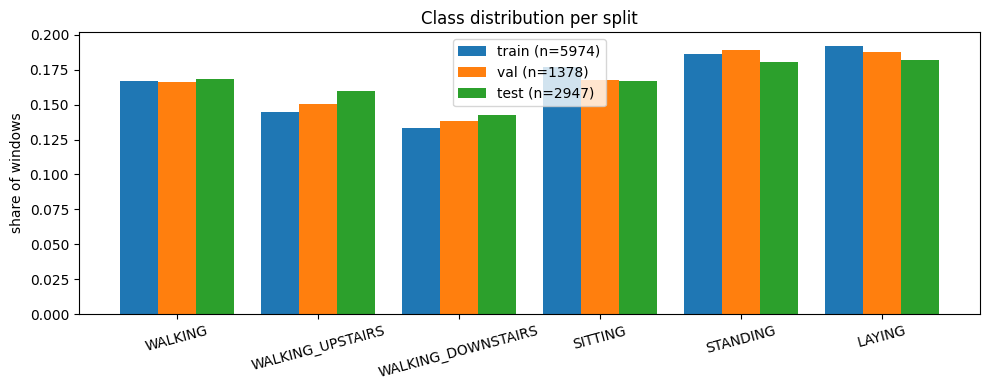

In [10]:
# ---------------------------------------------------------------- 8. Sanity check + class plot
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

lr = LogisticRegression(max_iter=3000, C=1.0)
lr.fit(splits["train"]["X_z"], splits["train"]["y"])
pred = lr.predict(splits["test"]["X_z"])
print(f"Logistic regression on processed features: test acc {accuracy_score(splits['test']['y'], pred):.4f}, "
      f"macro-F1 {f1_score(splits['test']['y'], pred, average='macro'):.4f}  (expected ≈ 0.96)")

fig, ax = plt.subplots(figsize=(10, 4))
w = 0.27
for i, k in enumerate(("train", "val", "test")):
    c = np.bincount(splits[k]["y"], minlength=6)
    ax.bar(np.arange(6) + (i - 1) * w, c / c.sum(), w, label=f"{k} (n={c.sum()})")
ax.set_xticks(range(6), CLASS_NAMES, rotation=15)
ax.set_ylabel("share of windows"); ax.set_title("Class distribution per split"); ax.legend()
fig.tight_layout(); fig.savefig(OUT_DIR / "figures" / "class_distribution.png", dpi=150)
plt.show()

## How to use the processed dataset (for every model)
See the comment block in the cell below - it is plain Python comments so it can be copied anywhere.

In [11]:
# =============================================================================================
#  HOW TO USE THE PROCESSED DATASET  (MLP / 1D CNN / LSTM / BiLSTM / Transformer)
# =============================================================================================
#
#  0) Folder layout after running this notebook once
#       MyDrive/DL PROJ/
#         ├── 01_HAR_Preprocessing.ipynb     (this notebook)
#         ├── har_common.py                  (shared loader + metrics + results writer)
#         ├── Dataset/                       (raw UCI files - never modified)
#         ├── processed/                     (written here: npz files, scalers, meta.json)
#         ├── transformer/  cnn/  lstm/  mlp/   (one folder per model; results go there)
#
#  1) In your model notebook (Colab):
#       from google.colab import drive; drive.mount('/content/drive')
#       import sys; sys.path.insert(0, '/content/drive/MyDrive/DL PROJ')
#       import har_common as hc
#
#  2) Load the data - pick the representation your model uses:
#       d = hc.load_data('sequence')                         # CNN / LSTM / BiLSTM / Transformer
#       d = hc.load_data('sequence', channels_first=True)    # (N, 9, 128) for PyTorch nn.Conv1d
#       d = hc.load_data('sequence', augmented=True)         # shared pre-augmented train set (11,948)
#       d = hc.load_data('tabular')                          # MLP on the 561 features
#
#       X_train, y_train = d['X_train'], d['y_train']        # float32 / int64 (labels 0..5)
#       X_val,   y_val   = d['X_val'],   d['y_val']
#       X_test,  y_test  = d['X_test'],  d['y_test']
#       subj_test        = d['subj_test']                    # needed for per-subject metrics
#       d['class_names'] -> ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS',
#                            'SITTING', 'STANDING', 'LAYING']
#
#     Without har_common (plain numpy):
#       z = np.load('/content/drive/MyDrive/DL PROJ/processed/sequence.npz')
#       X_train, y_train = z['X_train'], z['y_train']        # keys: X_/y_/subj_ + train/val/test
#
#  3a) PyTorch
#       import torch
#       from torch.utils.data import TensorDataset, DataLoader
#       tr = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
#       train_loader = DataLoader(tr, batch_size=64, shuffle=True)
#       # nn.LSTM(batch_first=True) and Transformers take (N, 128, 9) directly;
#       # nn.Conv1d wants (N, 9, 128) -> channels_first=True or x.transpose(1, 2).
#
#  3b) TensorFlow / Keras
#       model.fit(X_train, y_train, validation_data=(X_val, y_val), batch_size=64, epochs=200,
#                 callbacks=[...])                           # Conv1D / LSTM accept (N, 128, 9)
#       # loss='sparse_categorical_crossentropy' (labels are integers 0..5)
#
#  4) Protocol rules (keep the comparison fair)
#       * Use the processed data as saved. Never refit scalers or re-split.
#       * Select hyper-parameters / early-stop on VALIDATION macro-F1; touch the test set once.
#       * Seed 42. Validation and test sets are never augmented.
#
#  5) Save your results row (fills every column of the metrics checklist):
#       P_tr, P_va, P_te = class probabilities (N, 6) from your trained model (softmax outputs)
#       hc.save_results('/content/drive/MyDrive/DL PROJ/cnn/results.csv',
#           model_name='cnn', family='CNN', owner='Your Name',
#           input_representation='raw_9ch_128',              # or 'tabular_561' for the MLP
#           run_tag='tuned',                                 # 'baseline' / 'tuned' / 'augmented'
#           y_train=d['y_train'], proba_train=P_tr, y_val=d['y_val'], proba_val=P_va,
#           y_test=d['y_test'], proba_test=P_te, subj_test=d['subj_test'],
#           efficiency=dict(params_total=hc.count_params(model),
#                           model_size_mb=hc.file_size_mb('best_model.pt'),
#                           flops_per_window=hc.count_flops(model, (1, 128, 9)),   # PyTorch only
#                           latency_ms_cpu_b1=hc.measure_latency(model, (1, 128, 9), 'cpu'),
#                           latency_ms_gpu_b1=hc.measure_latency(model, (1, 128, 9), 'cuda'),
#                           throughput_gpu_wps=hc.measure_throughput(model, (128, 9)),
#                           peak_gpu_mem_mb=torch.cuda.max_memory_allocated() / 2**20),
#           training=dict(train_time_s=..., epochs_trained=..., best_epoch=..., time_per_epoch_s=...),
#           notes='FLOPs: torch.utils.flop_counter')
#       (Keras users: compute the efficiency numbers yourselves and pass them in the same dict.)
#
#  6) Check that meta.json -> dataset_version is the same in everyone's row. If anyone re-runs this
#     notebook with different settings, the fingerprint changes and all models must be re-run.
#
#  7) To feed NEW raw sensor windows to a trained sequence model, apply the same transform:
#       s = json.load(open('.../processed/sequence_scaler.json'))
#       x_z = (np.clip(x_raw, s['clip_lo'], s['clip_hi']) - s['mean']) / s['std']
# =============================================================================================